In [1]:
import pandas as pd
import numpy as np
import scipy
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from scipy.special import gamma as gamma
from scipy.optimize import root_scalar
import math

### Introducción:
El análisis exploratorio nos permite observar tendencias en los datos deportivos, pero para afirmar que estas tendencias son estadísticamente significativas necesitamos comprobarlas matemáticamente. Este análisis aplica métodos de inferencia estadística sobre la base de datos de FBref que usa el proyecto: **7,720 partidos jugados de La Liga (2006/07 a 2026/27)** y la **tabla general de 400 temporadas de equipo completas (2006/07 a 2025/26)**. Los estadísticos se calculan manualmente y los valores p se obtienen integrando numéricamente la función de densidad de cada distribución.

### Finalidad:
Validar empíricamente tres supuestos del fútbol que alimentan nuestro modelo predictivo: si la ventaja de jugar de local es real, si el nivel del equipo cambia su capacidad goleadora y si los goles por partido siguen una distribución de Poisson.

In [2]:
# Los CSV están en el repositorio; en Colab se leen directo de GitHub.
BASE_LOCAL = "data/fbref/processed/"
BASE_GITHUB = "https://raw.githubusercontent.com/GzzAlejandro/proyecto-integrador-laliga/main/data/fbref/processed/"

def leer(nombre):
    try:
        return pd.read_csv(BASE_LOCAL + nombre)
    except FileNotFoundError:
        return pd.read_csv(BASE_GITHUB + nombre)

df_partidos = leer("partidos_historico_completo.csv")
df_tabla = leer("tabla_general_historico_completo.csv")
df_partidos.head()

,Temporada,Wk,Day,Date,Time,Home,Score,Away,Attendance,Venue,Referee,Match Report,Notes
0,2006,1.0,Sat,2006-08-26,NaN,Valencia,2–1,Real Betis,NaN,Mestalla,Muñiz Fernández,Match Report,NaN
1,2006,1.0,Sun,2006-08-27,NaN,Athletic Club,1–1,Real Sociedad,NaN,San Mamés,Undiano Mallenco,Match Report,NaN
2,2006,1.0,Sun,2006-08-27,NaN,Dep. La Coruña,3–2,Zaragoza,NaN,Nuevo Riazor,Pérez Burrull,Match Report,NaN
3,2006,1.0,Sun,2006-08-27,NaN,Recreativo,1–1,Mallorca,NaN,Nuevo Colombino,Pino Zamorano,Match Report,NaN
4,2006,1.0,Sun,2006-08-27,NaN,Osasuna,0–2,Getafe,NaN,Reyno de Navarra,Pérez Lima,Match Report,NaN


In [3]:
# Partidos: se quitan los que aún no se juegan y se separan los goles del marcador "2–1"
df_partidos = df_partidos[df_partidos["Score"].notna()].copy()
marcador = df_partidos["Score"].str.split("–", expand=True).astype(int)
df_partidos["Goles_Local"] = marcador[0]
df_partidos["Goles_Visita"] = marcador[1]

# Tabla general: se corrige la temporada (607 -> 2006) y se usan solo temporadas completas
df_tabla = df_tabla[df_tabla["Squad"].notna()].copy()
df_tabla["Temporada"] = df_tabla["Temporada"].map(lambda x: 2000 + int(str(x).zfill(4)[:2]))
df_tabla = df_tabla[df_tabla["Temporada"] <= 2025]
for col in ["Rk", "MP", "GF"]:
    df_tabla[col] = pd.to_numeric(df_tabla[col], errors="coerce")

print(f"Partidos jugados: {len(df_partidos):,} | Temporadas de equipo: {len(df_tabla)}")

Partidos jugados: 7,720 | Temporadas de equipo: 400


### Pruebas de Hipótesis e Inferencia Estadística

Para validar la robustez de las variables que alimentan nuestro modelo predictivo sobre los resultados de La Liga, se usaron los partidos y la tabla general de FBref. Se diseñaron tres pruebas de hipótesis, fundamentadas teóricamente y calculadas mediante integración numérica de sus respectivas funciones de densidad de probabilidad (PDF). Nivel de significancia: **α = 0.05**.

#### 1. Observaciones Pareadas (Distribución T de Student)
Se evaluó si existe una "ventaja de localía" significativa, comparando en cada partido los goles del equipo local contra los del visitante.
* **Hipótesis Nula ($H_0$):** La diferencia promedio poblacional entre los goles anotados por el local y los goles anotados por el visitante por partido es igual a cero (no existe ventaja de localía).
* **Hipótesis Alternativa ($H_a$):** La diferencia promedio poblacional es mayor a cero (existe una ventaja estadísticamente significativa de jugar en casa).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I (Falso Positivo):* Rechazar $H_0$ cuando es verdadera. Implicaría concluir que jugar de local da ventaja cuando en la realidad no la da. **Riesgo:** El modelo sobrestimaría las probabilidades de victoria del equipo local, sesgando los pronósticos hacia resultados irreales y reduciendo el *accuracy* global.
* *Error Tipo II (Falso Negativo):* No rechazar $H_0$ cuando $H_a$ es verdadera. **Riesgo:** El modelo trataría los partidos de local y visitante por igual, perdiendo una variable explicativa fundamental en el fútbol y provocando predicciones planas y subajustadas (underfitting).

#### 2. Análisis de Varianza - ANOVA (Distribución F de Fisher)
Se analizó si existe una diferencia significativa en la capacidad goleadora promedio (goles a favor por partido en la temporada) entre tres niveles de equipos, según su posición final en la tabla: contendientes al título (lugares 1 a 4), media tabla (5 a 17) y descenso (18 a 20).
* **Hipótesis Nula ($H_0$):** El promedio poblacional de goles anotados por partido es idéntico para los equipos contendientes al título, los equipos de media tabla y los equipos en zona de descenso.
* **Hipótesis Alternativa ($H_a$):** Al menos uno de los tres grupos de equipos tiene un promedio poblacional de goles por partido significativamente diferente al de los demás.

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Concluir que los grupos tienen capacidades goleadoras distintas cuando son estadísticamente iguales. **Riesgo:** Asignaríamos pesos excesivos a la jerarquía histórica del equipo en el algoritmo de Machine Learning, perjudicando la predicción en partidos donde los equipos están nivelados.
* *Error Tipo II:* Concluir que todos los grupos anotan igual cuando hay diferencias. **Riesgo:** El modelo no podría discriminar partidos asimétricos (ej. líder vs último lugar), fracasando en identificar las victorias predecibles con alta probabilidad.

#### 3. Bondad de Ajuste (Distribución Chi-Cuadrada)
Para modelar correctamente la distribución de goles con miras a la simulación Monte Carlo, se probó si los goles totales por partido se ajustan a una Distribución de Poisson.
* **Hipótesis Nula ($H_0$):** La frecuencia de los goles anotados por partido en La Liga sigue una distribución de probabilidad de Poisson.
* **Hipótesis Alternativa ($H_a$):** La frecuencia de los goles anotados por partido en La Liga no sigue una distribución de Poisson (existe sobredispersión o dependencia).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Rechazar que los goles siguen una distribución Poisson cuando sí lo hacen. **Riesgo:** Descartaríamos un modelo matemático simple, obligándonos a programar distribuciones más costosas a nivel computacional (como la Binomial Negativa), aumentando la complejidad sin beneficio real.
* *Error Tipo II:* Asumir que los goles siguen una distribución Poisson cuando no es cierto. **Riesgo:** Las estimaciones probabilísticas de resultados exactos (ej. 2-1 o 0-0) estarían viciadas, afectando la pérdida logarítmica (Log Loss) del sistema de clasificación.

**Nota sobre la función Gamma:** con miles de datos, los grados de libertad son muy grandes y `gamma()` se desborda (por ejemplo, Γ(3860) es demasiado grande para una computadora). Por eso, dentro de las densidades se usa el logaritmo de la función Gamma (`math.lgamma`) y se regresa al valor con la exponencial; matemáticamente es la misma fórmula.

In [4]:
# =========================================================
# 1. OBSERVACIONES PAREADAS (T-STUDENT)
# =========================================================
def pdf_t_student(t, df):
    """Función de densidad de probabilidad para T-Student."""
    # coef = gamma((df+1)/2) / (sqrt(df*pi) * gamma(df/2)), calculado con logaritmos
    log_coef = math.lgamma((df + 1) / 2) - math.lgamma(df / 2) - 0.5 * np.log(df * np.pi)
    return np.exp(log_coef) * (1 + (t**2) / df)**(-(df + 1) / 2)

def prueba_pareada_manual(local_goals, away_goals):
    diferencias = local_goals - away_goals
    n = len(diferencias)
    df = n - 1

    media_dif = np.mean(diferencias)
    # std muestral con grados de libertad n-1
    std_dif = np.sqrt(np.sum((diferencias - media_dif)**2) / df)

    # Estadístico T
    t_stat = media_dif / (std_dif / np.sqrt(n))

    # P-valor integrando la PDF desde t_stat hasta infinito (cola derecha, H_a: mayor a cero)
    p_value, _ = integrate.quad(pdf_t_student, t_stat, np.inf, args=(df,))

    return t_stat, p_value, df, media_dif, std_dif

In [5]:
# =========================================================
# 2. ANOVA DE UN FACTOR (F-FISHER)
# =========================================================
def pdf_f_fisher(x, df1, df2):
    """Función de densidad de probabilidad para F-Fisher."""
    if x <= 0:
        return 0.0
    # Función Beta usando Gamma: B = gamma(df1/2) * gamma(df2/2) / gamma((df1+df2)/2), con logaritmos
    log_beta = math.lgamma(df1 / 2) + math.lgamma(df2 / 2) - math.lgamma((df1 + df2) / 2)
    log_num = (df1 / 2) * np.log(df1 / df2) + (df1 / 2 - 1) * np.log(x)
    log_den = ((df1 + df2) / 2) * np.log(1 + (df1 / df2) * x)
    return np.exp(log_num - log_den - log_beta)

def anova_manual(*grupos):
    k = len(grupos)
    n_i = [len(g) for g in grupos]
    N = sum(n_i)
    df1 = k - 1
    df2 = N - k

    media_global = np.mean(np.concatenate(grupos))

    # Suma de cuadrados
    ssb = sum(n_i[i] * (np.mean(grupos[i]) - media_global)**2 for i in range(k))
    ssw = sum(sum((x - np.mean(grupos[i]))**2 for x in grupos[i]) for i in range(k))

    msb = ssb / df1
    msw = ssw / df2
    f_stat = msb / msw

    # P-valor integrando (cola derecha)
    p_value, _ = integrate.quad(pdf_f_fisher, f_stat, np.inf, args=(df1, df2))

    return f_stat, p_value, df1, df2, ssb, ssw

In [6]:
# =========================================================
# 3. BONDAD DE AJUSTE (CHI-CUADRADA para POISSON)
# =========================================================
def pdf_chi2(x, df):
    """Función de densidad de probabilidad para Chi-Cuadrada."""
    if x <= 0:
        return 0.0
    return (x**(df/2 - 1) * np.exp(-x/2)) / (2**(df/2) * gamma(df/2))

def poisson_prob(k, lam):
    """Probabilidad de distribución de Poisson usando función gamma para factorial."""
    return (lam**k * np.exp(-lam)) / gamma(k + 1)

def chi2_bondad_ajuste_poisson(goles_observados):
    # Frecuencias observadas para 0, 1, 2, 3, 4, 5 y 6+ goles
    conteos, _ = np.histogram(goles_observados, bins=[0, 1, 2, 3, 4, 5, 6, np.inf])
    n_total = len(goles_observados)

    # Lambda estimado (media de goles)
    lam = np.mean(goles_observados)

    # Frecuencias esperadas
    probs = [poisson_prob(i, lam) for i in range(6)]
    probs.append(1 - sum(probs))  # Todo lo >= 6
    esperados = np.array(probs) * n_total

    # Estadístico Chi-Cuadrado
    chi_stat = np.sum((conteos - esperados)**2 / esperados)

    # Grados de libertad: categorías (7) - 1 - parámetros estimados (1) = 5
    df = len(conteos) - 1 - 1

    # P-valor (cola derecha)
    p_value, _ = integrate.quad(pdf_chi2, chi_stat, np.inf, args=(df,))

    return chi_stat, p_value, df, conteos, esperados, lam

### Ejecución con los datos reales

In [7]:
goles_local = df_partidos["Goles_Local"].to_numpy(dtype=float)
goles_visitante = df_partidos["Goles_Visita"].to_numpy(dtype=float)
goles_totales = goles_local + goles_visitante

df_tabla["Goles_por_partido"] = df_tabla["GF"] / df_tabla["MP"]
goles_contendientes = df_tabla.loc[df_tabla["Rk"] <= 4, "Goles_por_partido"].to_numpy()
goles_mediatabla = df_tabla.loc[(df_tabla["Rk"] >= 5) & (df_tabla["Rk"] <= 17), "Goles_por_partido"].to_numpy()
goles_descenso = df_tabla.loc[df_tabla["Rk"] >= 18, "Goles_por_partido"].to_numpy()

def formato_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.4f}"

# --- EJECUTAR PRUEBAS ---
t_stat, p_val_t, df_t, media_dif, std_dif = prueba_pareada_manual(goles_local, goles_visitante)
f_stat, p_val_f, df1_f, df2_f, ssb, ssw = anova_manual(goles_contendientes, goles_mediatabla, goles_descenso)
chi_stat, p_val_chi, df_chi, obs, esp, lam = chi2_bondad_ajuste_poisson(goles_totales)

# --- IMPRIMIR RESULTADOS ---
print("--- 1. T-Student Pareada ---")
print(f"n = {len(goles_local)} partidos | local: {goles_local.mean():.3f} | visitante: {goles_visitante.mean():.3f}")
print(f"Diferencia media: {media_dif:.3f} | Desv. est.: {std_dif:.3f} | gl = {df_t}")
print(f"Estadístico T: {t_stat:.4f} | P-Valor: {p_val_t:.3e} ({formato_p(p_val_t)})")
print("Conclusión: Rechazamos H0." if p_val_t < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 2. ANOVA de 1 Factor ---")
for nombre, g in [("Contendientes (1-4)", goles_contendientes), ("Media tabla (5-17)", goles_mediatabla), ("Descenso (18-20)", goles_descenso)]:
    print(f"{nombre:20s} n = {len(g):3d} | media = {g.mean():.3f} goles por partido")
print(f"SCE = {ssb:.3f} | SCD = {ssw:.3f} | gl = ({df1_f}, {df2_f})")
print(f"Estadístico F: {f_stat:.4f} | P-Valor: {p_val_f:.3e} ({formato_p(p_val_f)})")
print("Conclusión: Rechazamos H0." if p_val_f < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---")
print(pd.DataFrame({"Goles": ["0", "1", "2", "3", "4", "5", "6+"], "Observados": obs, "Esperados": esp.round(1)}).to_string(index=False))
print(f"Lambda = {lam:.3f} | Varianza = {np.var(goles_totales, ddof=1):.3f} | gl = {df_chi}")
print(f"Estadístico Chi2: {chi_stat:.4f} | P-Valor: {p_val_chi:.3e} ({formato_p(p_val_chi)})")
print("Conclusión: Rechazamos H0 (No es Poisson)." if p_val_chi < 0.05 else "Conclusión: No rechazamos H0 (Sigue Poisson).")

--- 1. T-Student Pareada ---
n = 7720 partidos | local: 1.542 | visitante: 1.135
Diferencia media: 0.406 | Desv. est.: 1.769 | gl = 7719
Estadístico T: 20.1823 | P-Valor: 1.291e-88 (p < 0.001)
Conclusión: Rechazamos H0.

--- 2. ANOVA de 1 Factor ---
Contendientes (1-4)  n =  80 | media = 2.035 goles por partido
Media tabla (5-17)   n = 260 | media = 1.208 goles por partido
Descenso (18-20)     n =  60 | media = 0.966 goles por partido
SCE = 51.574 | SCD = 38.398 | gl = (2, 397)
Estadístico F: 266.6120 | P-Valor: 3.938e-74 (p < 0.001)
Conclusión: Rechazamos H0.

--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---
Goles  Observados  Esperados
    0         581      530.7
    1        1440     1420.9
    2        1870     1902.1
    3        1700     1697.5
    4        1024     1136.2
    5         616      608.4
   6+         489      424.0
Lambda = 2.677 | Varianza = 2.869 | gl = 5
Estadístico Chi2: 26.6960 | P-Valor: 6.537e-05 (p < 0.001)
Conclusión: Rechazamos H0 (No es Poisson).


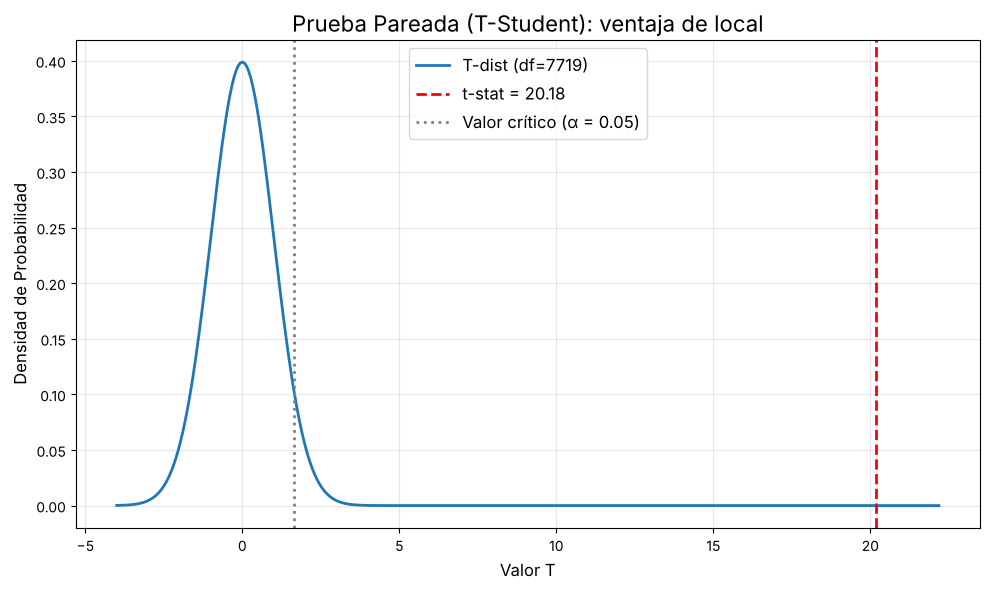

In [8]:
# Gráfico 1: T-Student
plt.figure(figsize=(10, 6))
x_t = np.linspace(-4, max(4, t_stat + 2), 400)
y_t = [pdf_t_student(val, df_t) for val in x_t]
plt.plot(x_t, y_t, label=f"T-dist (df={df_t})", linewidth=2)
plt.axvline(t_stat, color='red', linestyle='--', linewidth=2, label=f"t-stat = {t_stat:.2f}")
plt.axvline(1.645, color='gray', linestyle=':', linewidth=2, label="Valor crítico (α = 0.05)")
plt.fill_between(x_t, y_t, where=(x_t >= t_stat), color='red', alpha=0.3)
plt.title("Prueba Pareada (T-Student): ventaja de local", fontsize=16)
plt.xlabel("Valor T", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

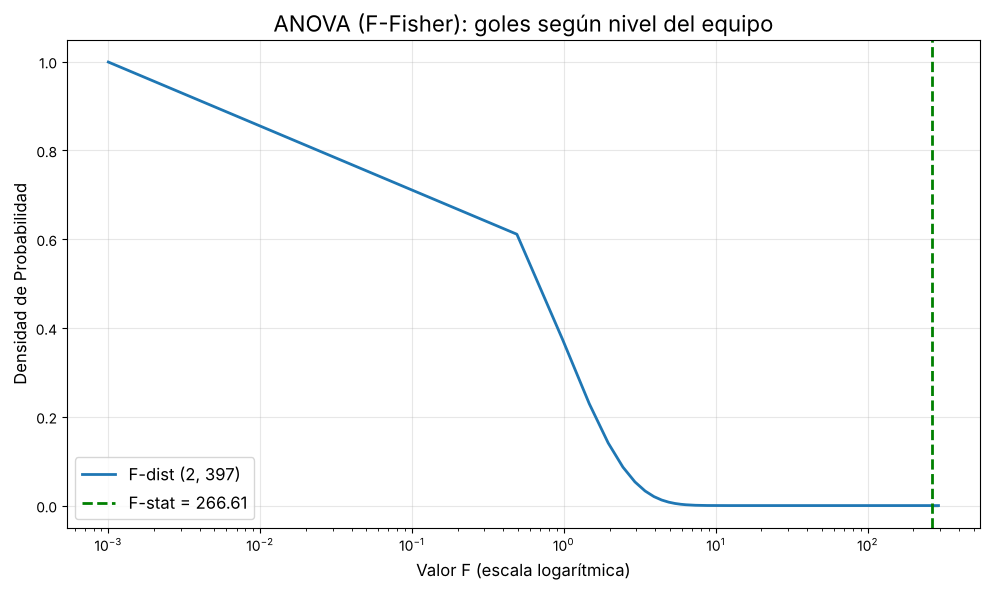

In [9]:
# Gráfico 2: ANOVA F
plt.figure(figsize=(10, 6))
x_f = np.linspace(0.001, max(8, f_stat * 1.1), 600)
y_f = [pdf_f_fisher(val, df1_f, df2_f) for val in x_f]
plt.plot(x_f, y_f, label=f"F-dist ({df1_f}, {df2_f})", linewidth=2)
plt.axvline(f_stat, color='green', linestyle='--', linewidth=2, label=f"F-stat = {f_stat:.2f}")
plt.fill_between(x_f, y_f, where=(x_f >= f_stat), color='green', alpha=0.3)
plt.xscale('log')
plt.title("ANOVA (F-Fisher): goles según nivel del equipo", fontsize=16)
plt.xlabel("Valor F (escala logarítmica)", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

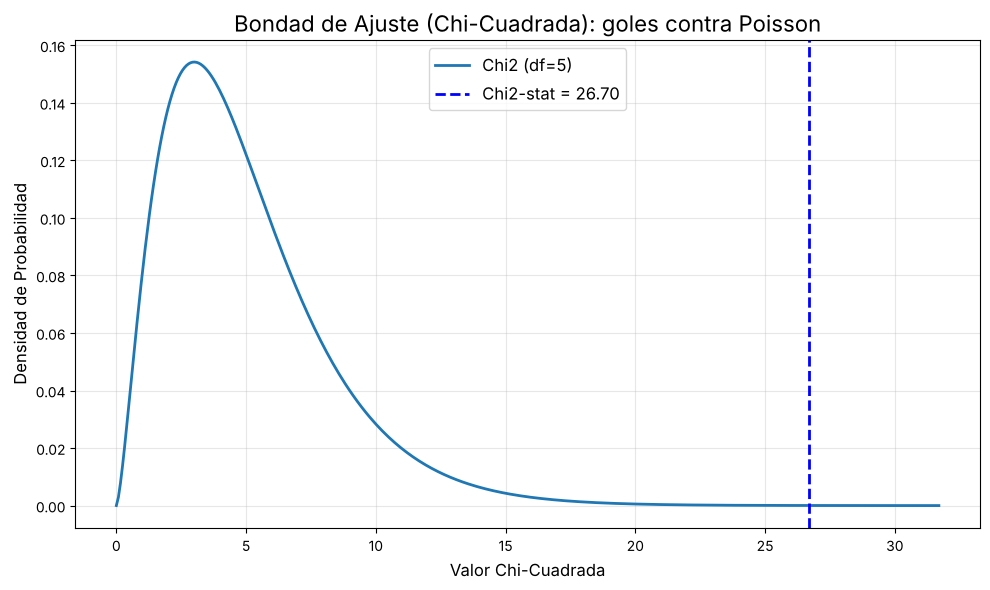

In [10]:
# Gráfico 3: Chi-Cuadrada
plt.figure(figsize=(10, 6))
x_c = np.linspace(0.001, max(15, chi_stat + 5), 400)
y_c = [pdf_chi2(val, df_chi) for val in x_c]
plt.plot(x_c, y_c, label=f"Chi2 (df={df_chi})", linewidth=2)
plt.axvline(chi_stat, color='blue', linestyle='--', linewidth=2, label=f"Chi2-stat = {chi_stat:.2f}")
plt.fill_between(x_c, y_c, where=(x_c >= chi_stat), color='blue', alpha=0.3)
plt.title("Bondad de Ajuste (Chi-Cuadrada): goles contra Poisson", fontsize=16)
plt.xlabel("Valor Chi-Cuadrada", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

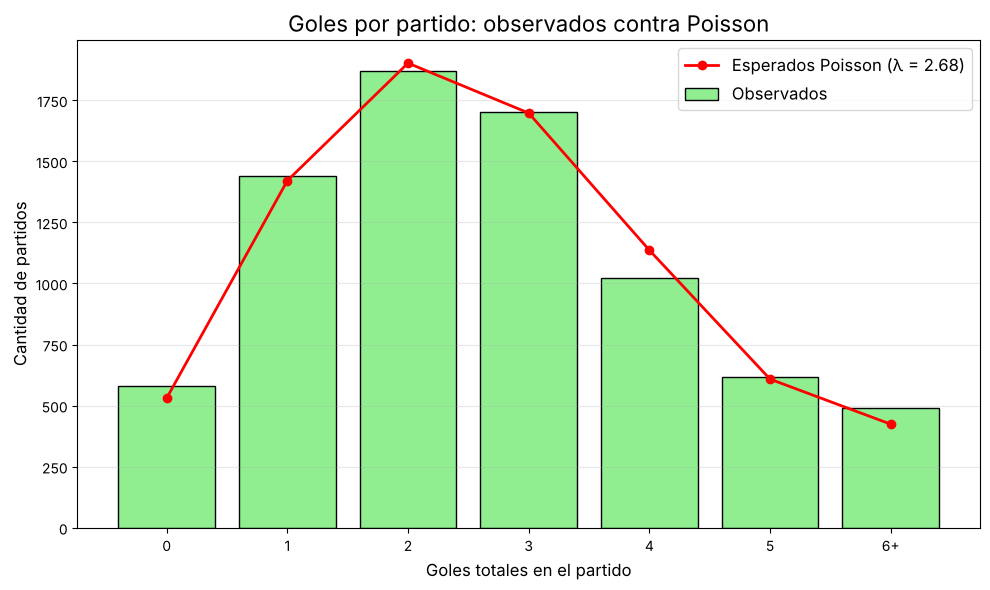

In [11]:
# Gráfico 4: goles observados contra Poisson
etiquetas = ["0", "1", "2", "3", "4", "5", "6+"]
x = np.arange(len(etiquetas))
plt.figure(figsize=(10, 6))
plt.bar(x, obs, color='lightgreen', edgecolor='black', label='Observados')
plt.plot(x, esp, 'o-', color='red', linewidth=2, label=f'Esperados Poisson (λ = {lam:.2f})')
plt.xticks(x, etiquetas)
plt.title("Goles por partido: observados contra Poisson", fontsize=16)
plt.xlabel("Goles totales en el partido", fontsize=12)
plt.ylabel("Cantidad de partidos", fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Justificación y Conclusiones

**Problema 1: Ventaja de local (T-Student pareada).**
Decisión: se rechaza $H_0$ (t = 20.18, gl = 7,719, p < 0.001).
Justificación: el valor p es mucho menor que α = 0.05; la probabilidad de observar esta diferencia por simple azar es prácticamente nula.
Conclusión: el local anota en promedio 1.54 goles y el visitante 1.14, una diferencia de 0.41 goles por partido. La ventaja de local es real, lo que justifica incluirla en el modelo y explica por qué “siempre gana el local” es una referencia difícil de superar.

**Problema 2: Goles según el nivel del equipo (ANOVA).**
Decisión: se rechaza $H_0$ (F = 266.61, gl = (2, 397), p < 0.001).
Justificación: el valor p es menor que 0.05, por lo que al menos un grupo tiene un promedio distinto.
Conclusión: los contendientes anotan 2.04 goles por partido, la media tabla 1.21 y los equipos que descienden 0.97. El nivel del equipo cambia mucho su capacidad goleadora, así que el modelo necesita variables de fuerza del equipo.

**Problema 3: Goles por partido contra Poisson (Chi-cuadrada).**
Decisión: se rechaza $H_0$ (χ² = 26.70, gl = 5, p < 0.001).
Justificación: el valor p es menor que 0.05, así que las diferencias entre lo observado y lo esperado no se explican por azar.
Conclusión: los goles no siguen exactamente una Poisson: hay más partidos de 0 goles y de 6 o más, y menos de 4, de lo que Poisson espera (varianza 2.87 contra media 2.68, sobredispersión). La forma general sí se parece, por lo que Poisson sirve como aproximación, pero para la simulación Monte Carlo convendría considerar una Binomial Negativa o un λ distinto para cada equipo.